# Dimensionality Reduction + Unsupervised

In [151]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.decomposition import PCA, KernelPCA
from sklearn import manifold
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from umap import UMAP
from sklearn.manifold import trustworthiness, TSNE
from sklearn.cluster import KMeans

from sklearn.metrics import silhouette_score, silhouette_samples

## Import Data

In [11]:
df = pd.read_csv(r'C:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\data\processed\model_dataset.csv')
df.head()

,unit_id,led_type,paste,panel,led,has_thermal_pad,thermal_void_area_frac,thermal_centroid_x,thermal_centroid_y,thermal_q_NW,...,label_status,tsc_fail,tsc_fail_sustained,last_cycle,rth_500,rth_end,rth_increase,rth_increase_pct,ri_500_pct,ri_max_pct
0,FC-GB2_SAC107-BiIn_P1_L02,FC-GB2,SAC107-BiIn,1,2,1.0,0.020928,0.615373,0.072432,0.000000,...,ok,500.0,500.0,1500.0,12.084356,29.839828,20.264891,211.645181,26.208211,211.645181
1,FC-GB2_SAC107-BiIn_P1_L03,FC-GB2,SAC107-BiIn,1,3,1.0,0.010285,-0.529327,0.457574,0.174419,...,ok,750.0,750.0,1500.0,10.744296,16.605415,7.029735,73.412388,12.204009,73.412388
2,FC-GB2_SAC107-BiIn_P1_L04,FC-GB2,SAC107-BiIn,1,4,1.0,0.045802,0.497724,0.012773,0.000000,...,ok,750.0,750.0,1500.0,9.556831,14.151400,4.538046,47.205646,-0.587963,47.205646
3,FC-GB2_SAC107-BiIn_P1_L05,FC-GB2,SAC107-BiIn,1,5,1.0,0.004186,-0.166625,0.228571,0.000000,...,ok,500.0,500.0,1500.0,11.691541,16.517620,6.980075,73.185239,22.584383,73.185239
4,FC-GB2_SAC107-BiIn_P1_L06,FC-GB2,SAC107-BiIn,1,6,1.0,0.002511,0.026549,0.486486,0.000000,...,ok,500.0,500.0,1500.0,12.173268,17.237209,7.815018,82.942673,29.197835,82.942673


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 45 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   unit_id                             1470 non-null   str    
 1   led_type                            1470 non-null   str    
 2   paste                               1470 non-null   str    
 3   panel                               1470 non-null   int64  
 4   led                                 1470 non-null   int64  
 5   has_thermal_pad                     1470 non-null   float64
 6   thermal_void_area_frac              1470 non-null   float64
 7   thermal_centroid_x                  1470 non-null   float64
 8   thermal_centroid_y                  1470 non-null   float64
 9   thermal_q_NW                        1470 non-null   float64
 10  thermal_q_NE                        1470 non-null   float64
 11  thermal_q_SW                        1470 non-null   fl

## Add binary label

In [13]:
survivor_label = []
for i in range(len(df['tsc_fail'])):
    if df['tsc_fail'].iloc[i] < 1600:
        survivor_label.append(0)
    else:
        survivor_label.append(1)

df['survivor_label'] = survivor_label
# print(df['survivor_label'])
df['survivor_label'].value_counts()

survivor_label
0    1055
1     415
Name: count, dtype: int64

## Prepare the Feature Matrix

In [14]:
thermal_cols = [c for c in df.columns if c.startswith("thermal_")]
elec_cols    = [c for c in df.columns if c.startswith("electrical_mean_")]
feat_cols    = thermal_cols + elec_cols 
print("Feature column length:", len(feat_cols))
print("Feature columns:", feat_cols)

# there are cell without values in the dataset, use imputer
# scale also the data before dim reduction and unsupervised
x = SimpleImputer(strategy='constant', fill_value=0).fit_transform(df[feat_cols])
x_scaled = StandardScaler().fit_transform(x)
print("Scaled feature shape:", x_scaled.shape)

Feature column length: 22
Feature columns: ['thermal_void_area_frac', 'thermal_centroid_x', 'thermal_centroid_y', 'thermal_q_NW', 'thermal_q_NE', 'thermal_q_SW', 'thermal_q_SE', 'thermal_cluster_count', 'thermal_mean_circularity', 'thermal_largest_void_frac', 'thermal_edge_proximity_min', 'electrical_mean_void_area_frac', 'electrical_mean_centroid_x', 'electrical_mean_centroid_y', 'electrical_mean_q_NW', 'electrical_mean_q_NE', 'electrical_mean_q_SW', 'electrical_mean_q_SE', 'electrical_mean_cluster_count', 'electrical_mean_mean_circularity', 'electrical_mean_largest_void_frac', 'electrical_mean_edge_proximity_min']
Scaled feature shape: (1470, 22)


## Exploratory Data Analysis

## Dimensionality Reduction

Use PCA, KPCA, Isomap, UMAP to try to reduce dimension

In [20]:
# dictionary where we will put all the best embeddings
embeddings = {}

### PCA

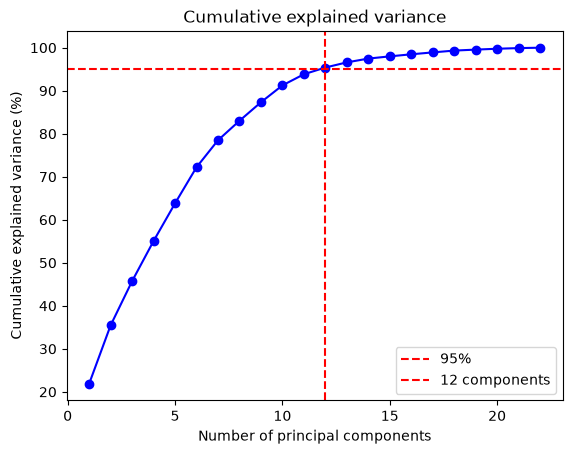

(1470, 12)
Number of components for 95% CPV: 12
Shape of PCA result for 95% CPV: (1470, 12)


In [190]:
def pca_analysis(x_scaled, feat_cols):
    # optimize PCA
    pca = PCA(n_components=len(feat_cols))
    pca_result = pca.fit_transform(x_scaled)
    var = pca.explained_variance_ratio_
    cpv = np.cumsum(var)*100
    
    

    # plot the cumulative percent variance
    plt.plot(np.arange(cpv.size)+1, cpv, 'bo-')
    plt.xlabel('Number of principal components')
    plt.ylabel('Cumulative explained variance (%)')
    plt.title('Cumulative explained variance')
    plt.axhline(95, color='r', linestyle='--', label='95%')
    plt.axvline(np.argmax(cpv >= 95) + 1, color='r', linestyle='--', label=f'{np.argmax(cpv >= 95) + 1} components')
    plt.legend()
    plt.grid(True)
    plt.grid()
    plt.show()

    n_components = np.argmax(cpv >= 95) + 1
    pca_df = pd.DataFrame(pca_result[:, :n_components], columns=[f'PC{i+1}' for i in range(n_components)])
    print(pca_df.shape)

    # pca data with 95% CPV
    n_components_95 = np.argmax(cpv >= 95) + 1
    pca_95 = PCA(n_components=n_components_95)
    pca_result_95 = pca_95.fit_transform(x_scaled)
    pca_result_95_df = pd.DataFrame(pca_result_95, columns=[f'PC{i+1}' for i in range(n_components_95)])
    print(f'Number of components for 95% CPV: {n_components_95}')
    print(f'Shape of PCA result for 95% CPV: {pca_result_95.shape}')

    return pca_result_95, pca_result_95_df

pca_df = pca_analysis(x_scaled, feat_cols)

# optimize PCA
# pca = PCA(n_components=len(feat_cols))
# pca_result = pca.fit_transform(x_scaled)
# var = pca.explained_variance_ratio_
# cpv = np.cumsum(var)*100

# # plot the cumulative percent variance
# plt.plot(np.arange(cpv.size)+1, cpv, 'bo-')
# plt.xlabel('Number of principal components')
# plt.ylabel('Cumulative explained variance (%)')
# plt.title('Cumulative explained variance')
# plt.axhline(95, color='r', linestyle='--', label='95%')
# plt.axvline(np.argmax(cpv >= 95) + 1, color='r', linestyle='--', label=f'{np.argmax(cpv >= 95) + 1} components')
# plt.legend()
# plt.grid(True)
# plt.grid()
# plt.show()

# pca_df = pd.DataFrame(pca_result[:, :12], columns=[f'PC{i+1}' for i in range(12)])
# print(pca_df.shape)
# pca_df.head()

In [187]:
# pca data with 95% CPV
n_components_95 = np.argmax(cpv >= 95) + 1
pca_95 = PCA(n_components=n_components_95)
pca_result_95 = pca_95.fit_transform(x_scaled)
pca_result_95_df = pd.DataFrame(pca_result_95, columns=[f'PC{i+1}' for i in range(n_components_95)])
print(f'Number of components for 95% CPV: {n_components_95}')
print(f'Shape of PCA result for 95% CPV: {pca_result_95.shape}')
embeddings['PCA'] = pca_result_95

print(f'Embeddings for PCA: {embeddings["PCA"].shape}')
pca_result_95_df.head()

Number of components for 95% CPV: 12
Shape of PCA result for 95% CPV: (1470, 12)
Embeddings for PCA: (1470, 12)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12
0,-1.444234,-0.868894,0.130200,2.057712,1.276376,3.747145,1.830149,0.560130,-0.716537,-1.641526,-0.372666,-1.173486
1,-0.642568,-4.827283,0.100872,-0.574332,-2.034888,0.444822,-2.467271,-0.096554,-1.236669,0.182779,0.712882,-0.295435
2,-1.537161,-3.860671,0.230221,0.918780,2.453337,0.617330,-2.757435,0.655930,1.637199,-1.686399,0.637474,-1.245342
3,-0.195140,-1.681555,-0.829848,-3.609944,-1.782421,0.950935,-0.868081,-1.223561,0.438222,2.576707,-0.477238,-1.025622
4,0.102638,-4.696709,0.636778,-0.194927,0.287323,2.172015,-2.574431,-0.434225,-1.759488,-1.506269,0.365888,-0.966030


#### Plotting and Inspection of 2 Principal Components

PCA showed that the dominant variance in the feature space is driven by the 'has_thermal_pad' feature. This might mean that we have to separate modeling the the with thermal pad and without thermal pad data.

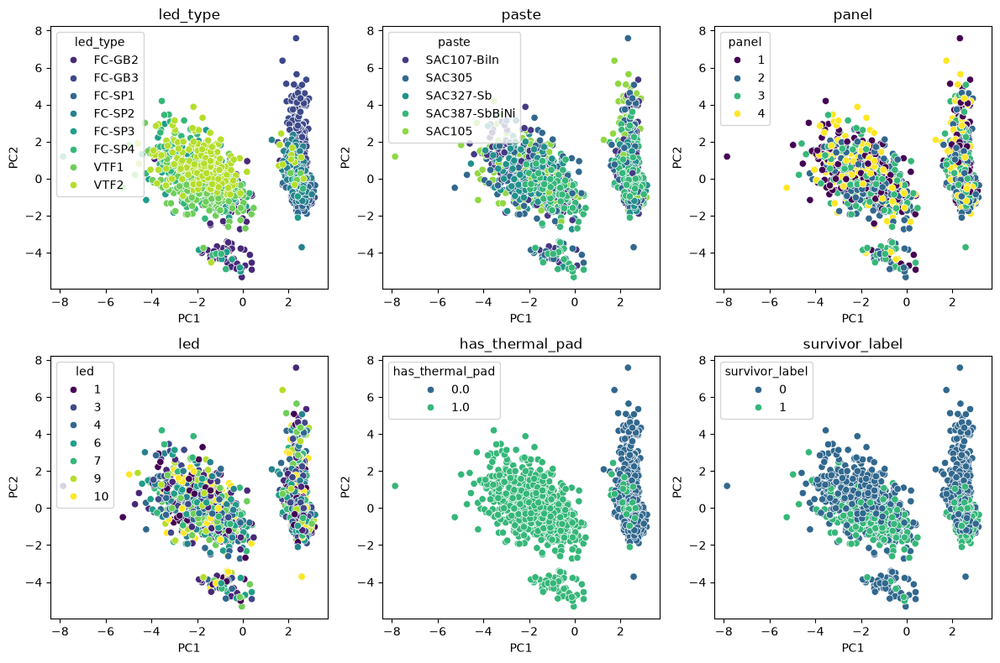

In [95]:
def inspect_dimreduction(df, dimred_result_df):

    fig, ax = plt.subplots(2, 3, figsize=(12, 8))

    for i, col in enumerate(['led_type', 'paste', 'panel', 'led', 'has_thermal_pad', 'survivor_label']):
        ax_i = ax[i // 3, i % 3]
        sns.scatterplot(data=dimred_result_df, x='PC1', y='PC2', hue=df[col], palette='viridis', ax=ax_i)
        ax_i.set_title(col)
    plt.tight_layout()
    plt.show()

inspect_dimreduction(df, pca_result_95_df)

### KPCA

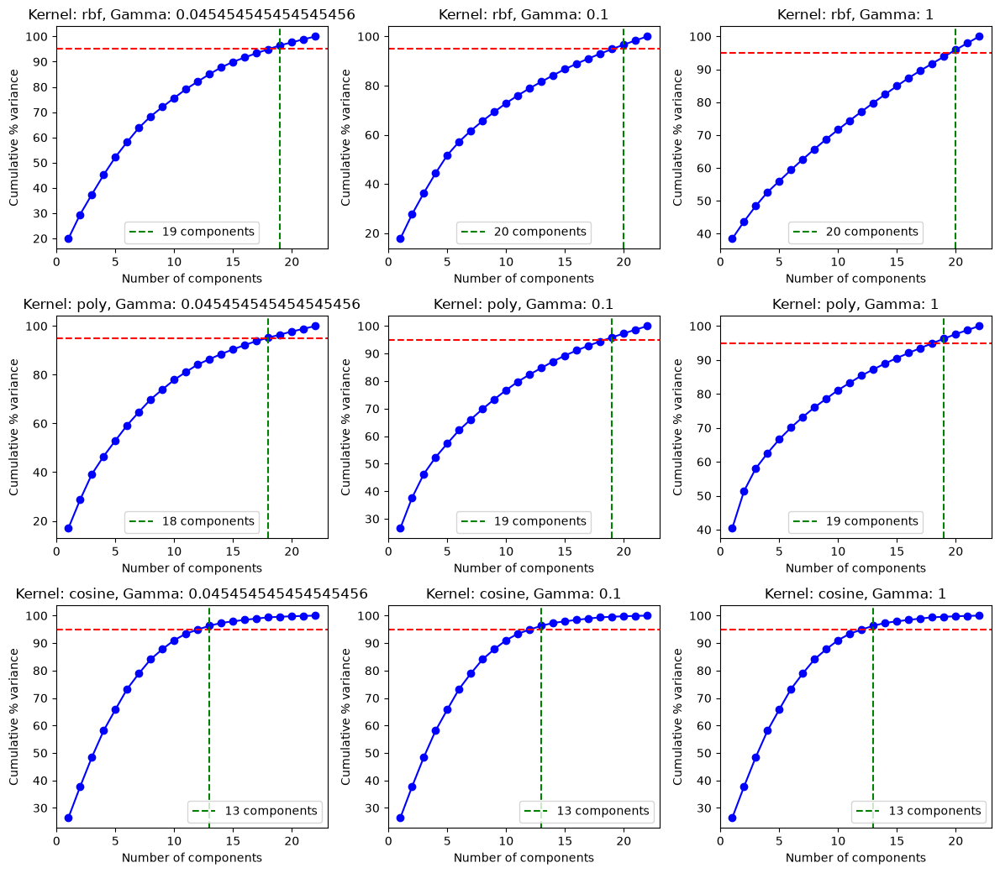

Best kernel: cosine, Best gamma: 0.045454545454545456, Minimum components: 13


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
0,-0.283183,-0.165768,0.165823,-0.366396,0.288974,0.582299,0.296140,-0.041265,0.314963,0.139581,-0.075551,-0.166012,-0.183200
1,-0.215144,-0.730232,0.100932,0.036334,0.267589,-0.219629,-0.461178,-0.144317,0.081734,-0.180962,0.151127,-0.032048,-0.056402
2,-0.301675,-0.562684,0.071095,-0.028961,-0.172644,0.386985,-0.468568,-0.099419,0.012637,0.384196,0.158817,-0.162691,-0.132438
3,-0.096687,-0.205800,0.218913,0.509861,0.417800,-0.231848,-0.244671,0.148418,-0.341334,-0.289470,-0.103318,-0.188536,-0.005289
4,-0.092572,-0.674338,0.070524,0.022329,0.254772,0.241785,-0.478595,-0.096422,0.352254,-0.080630,0.108729,-0.121707,-0.105335


In [48]:
kernel = ['rbf', 'poly', 'cosine']
gamma = [1/len(feat_cols), 0.1, 1]

fig, axes = plt.subplots(len(kernel), len(gamma),
                         figsize=(4 * len(gamma), 3.5 * len(kernel)),
                         squeeze=False)  # keeps axes 2D even if there's only 1 row or 1 column


# store the best kernel and gamma combination
best_kernel = None
best_gamma = None
min_components = float('inf')

for i, k in enumerate(kernel):
    for j, g in enumerate(gamma):
        kpca = KernelPCA(n_components=len(feat_cols), kernel=k, gamma=g)
        kpca_result = kpca.fit_transform(x_scaled)

        kpca_evratio = kpca.eigenvalues_ / kpca.eigenvalues_.sum()
        kpca_cpv = np.cumsum(kpca_evratio) * 100
        n95 = np.argmax(kpca_cpv >= 95) + 1

        ax = axes[i, j]
        ax.plot(np.arange(kpca_cpv.size) + 1, kpca_cpv, 'bo-')
        ax.axhline(y=95, color='r', linestyle='--')
        ax.axvline(x=n95, color='g', linestyle='--', label=f'{n95} components')
        if n95 < min_components:
            min_components = n95
            best_kernel = k
            best_gamma = g
        ax.set_title(f'Kernel: {k}, Gamma: {g}')
        ax.set_xlabel('Number of components')
        ax.set_ylabel('Cumulative % variance')
        ax.legend()

plt.tight_layout()
plt.show()

print(f'Best kernel: {best_kernel}, Best gamma: {best_gamma}, Minimum components: {min_components}')

kpca = KernelPCA(n_components=min_components, kernel=best_kernel, gamma=best_gamma)
kpca_result_95 = kpca.fit_transform(x_scaled)
kpca_result_95_df = pd.DataFrame(kpca_result_95, columns=[f'PC{i+1}' for i in range(min_components)])
embeddings['KPCA'] = kpca_result_95
kpca_result_95_df.head()



#### Plotting and Inspection of 2 Principal Components

Result of KPCA still shows that there is strong variance among the 'has_thermal_pad' feature.
<br>
And since the KPCA has 13 components, compared to PCA that has 12 components, we may opt to use PCA instead of KPCA dim reduction.

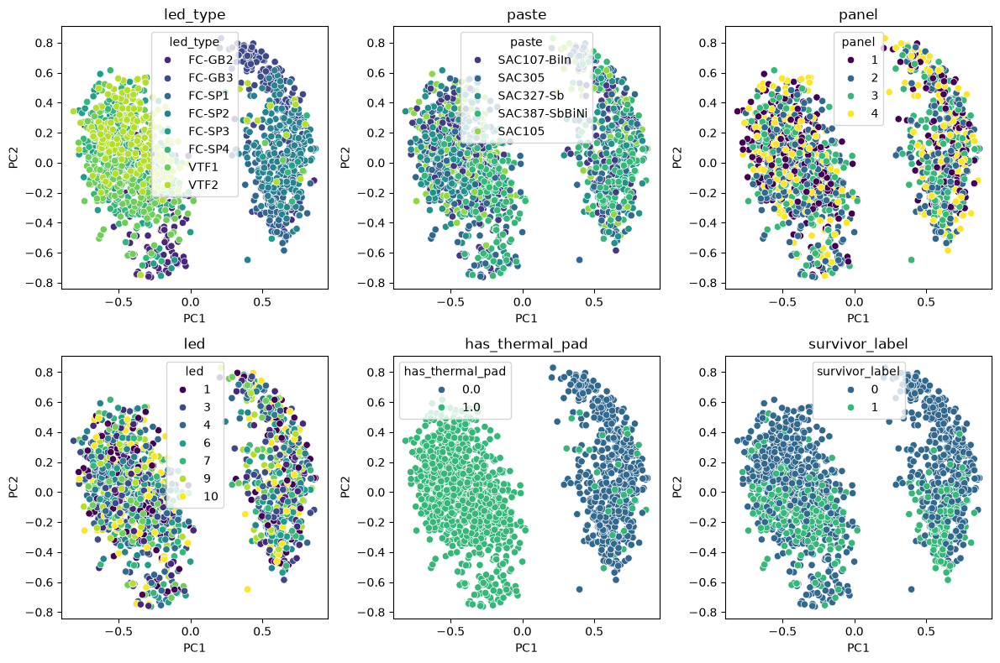

In [49]:
inspect_dimreduction(df, kpca_result_95_df)

### Isomap

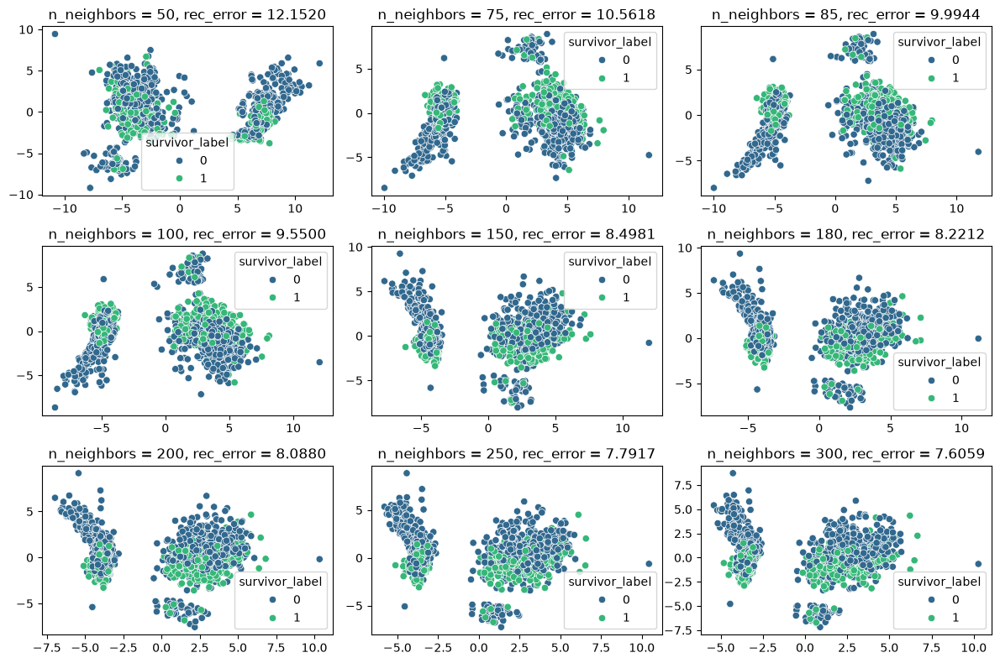

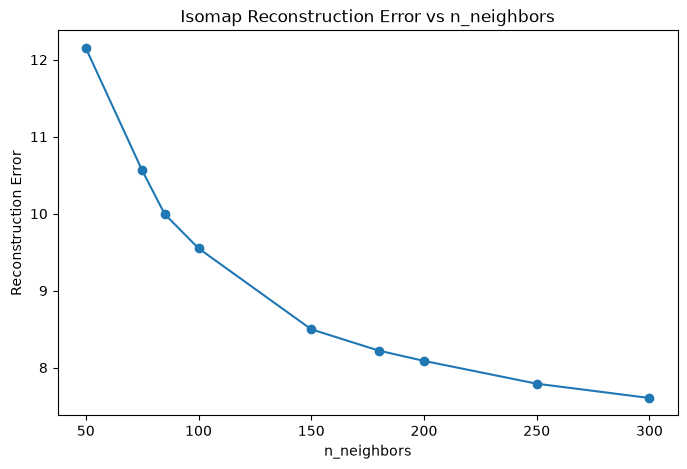

(1470, 2)

In [74]:
n_neighbors = [50, 75, 85, 100, 150, 180, 200, 250, 300]

# 2D Isomap visualization with varying n_neighbors
rec_errors = []

fig, ax = plt.subplots(3, 3, figsize=(12, 8))
for i, n in enumerate(n_neighbors):
    isomap = manifold.Isomap(n_components = 2, n_neighbors = n)
    isomap_result = isomap.fit_transform(x_scaled)
    rec_error = isomap.reconstruction_error()
    rec_errors.append(rec_error)
    ax_i = ax[i // 3, i % 3]
    sns.scatterplot(x=isomap_result[:, 0], y=isomap_result[:, 1], hue=df['survivor_label'], palette='viridis', ax=ax_i)
    ax_i.set_title(f'n_neighbors = {n}, rec_error = {rec_error:.4f}')
plt.tight_layout()
plt.show()

# plot the reconstruction error to determine which is the best hyperparameter --- lower is better
plt.figure(figsize=(8, 5))
plt.plot(n_neighbors, rec_errors, marker='o')
plt.xlabel('n_neighbors')
plt.ylabel('Reconstruction Error')
plt.title('Isomap Reconstruction Error vs n_neighbors')
plt.show()

isomap = manifold.Isomap(n_components=2, n_neighbors=150)
isomap_result_best = isomap.fit_transform(x_scaled)
isomap_result_best_df = pd.DataFrame(isomap_result_best, columns=[f'PC{i+1}' for i in range(2)])
embeddings['Isomap'] = isomap_result_best
isomap_result_best_df.shape


#### Plotting and Inspection

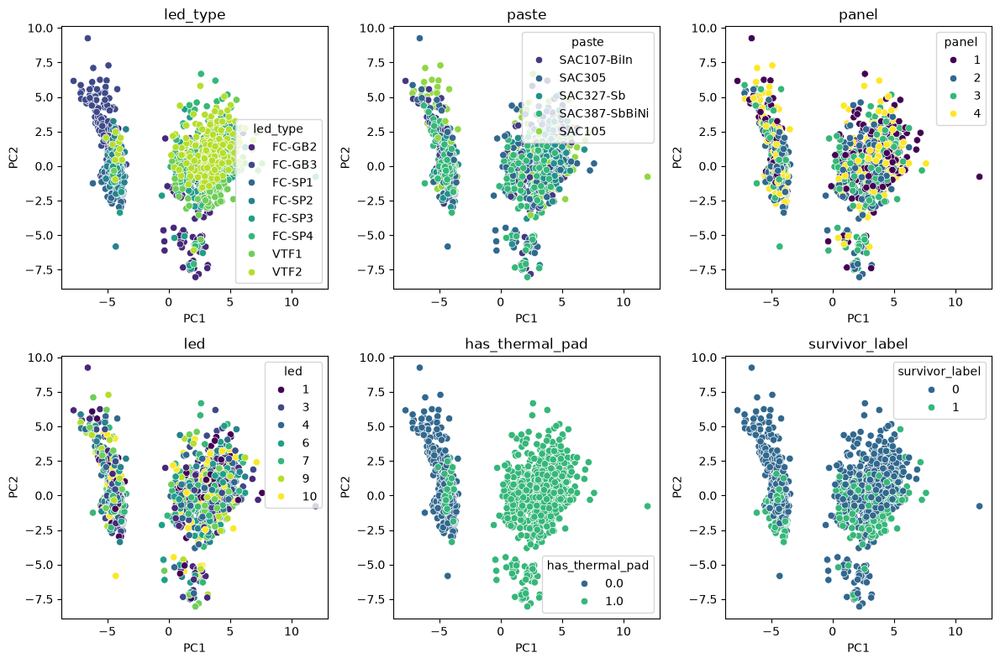

In [72]:
inspect_dimreduction(df, isomap_result_best_df)

### UMAP

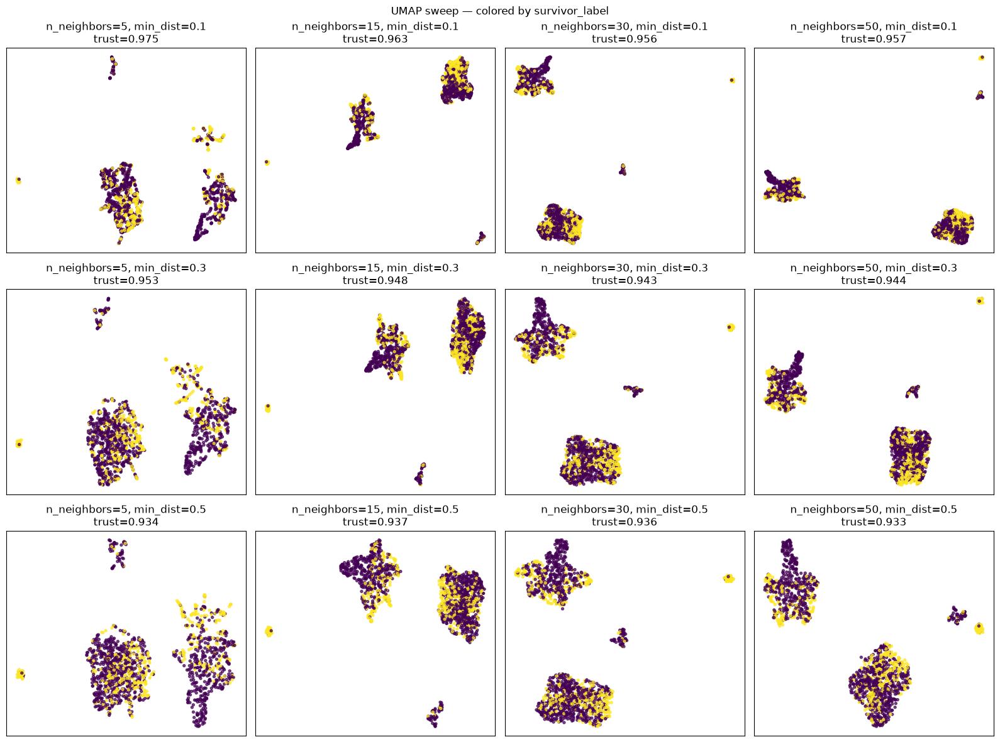


Top 5 by trustworthiness:
  n_neighbors=5, min_dist=0.1: 0.975
  n_neighbors=15, min_dist=0.1: 0.963
  n_neighbors=50, min_dist=0.1: 0.957
  n_neighbors=30, min_dist=0.1: 0.956
  n_neighbors=5, min_dist=0.3: 0.953


,PC1,PC2
0,6.518224,1.871373
1,2.558953,16.612453
2,2.230777,15.457875
3,1.921840,4.853564
4,2.677216,15.792253


In [93]:
n_neighbors = [5, 15, 30, 50]
min_dist = [0.1, 0.3, 0.5]

fig, axes = plt.subplots(len(min_dist), len(n_neighbors),
                         figsize=(16, 12))
trust_scores = {}

# 2D UMAP sweep with varying n_neighbors and min_dist

for i, md in enumerate(min_dist):
    for j, nn in enumerate(n_neighbors):
        reducer = UMAP(
            n_neighbors=nn,
            min_dist=md,
            n_components=2,
            random_state=42,
            n_jobs=1,                  # silences "n_jobs value -1 overridden to 1"
            compatibility_layout=True  # silences the FutureWarning and keeps current behavior
        )
        emb = reducer.fit_transform(x_scaled)
        trust = trustworthiness(x_scaled, emb, n_neighbors=5)
        trust_scores[(nn, md)] = trust

        ax = axes[i, j]
        ax.scatter(emb[:, 0], emb[:, 1], c=df['survivor_label'], cmap='viridis', s=8, alpha=0.7)
        ax.set_title(f'n_neighbors={nn}, min_dist={md}\ntrust={trust:.3f}')
        ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('UMAP sweep — colored by survivor_label')
plt.tight_layout(); plt.show()

# Rank combinations by trustworthiness
sorted_combos = sorted(trust_scores.items(), key=lambda x: -x[1])
print("\nTop 5 by trustworthiness:")
for (nn, md), score in sorted_combos[:5]:
    print(f"  n_neighbors={nn}, min_dist={md}: {score:.3f}")

# use the best parameter
best_nn, best_md = sorted_combos[0][0]
best_reducer = UMAP(
    n_neighbors=best_nn,
    min_dist=best_md,
    n_components=2,
    random_state=42,
    n_jobs=1,
    compatibility_layout=True
)
best_umap = best_reducer.fit_transform(x_scaled)
best_umap_df = pd.DataFrame(best_umap, columns=[f'PC{i+1}' for i in range(2)])
embeddings['UMAP2D'] = best_umap_df
best_umap_df.head()

#### Inspect

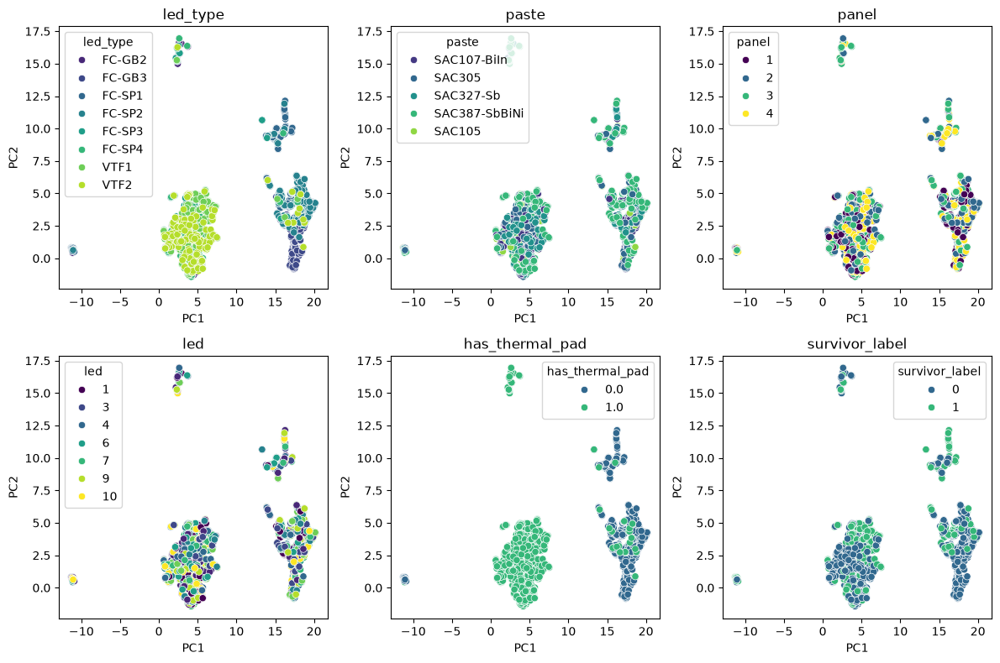

In [96]:
inspect_dimreduction(df, best_umap_df)

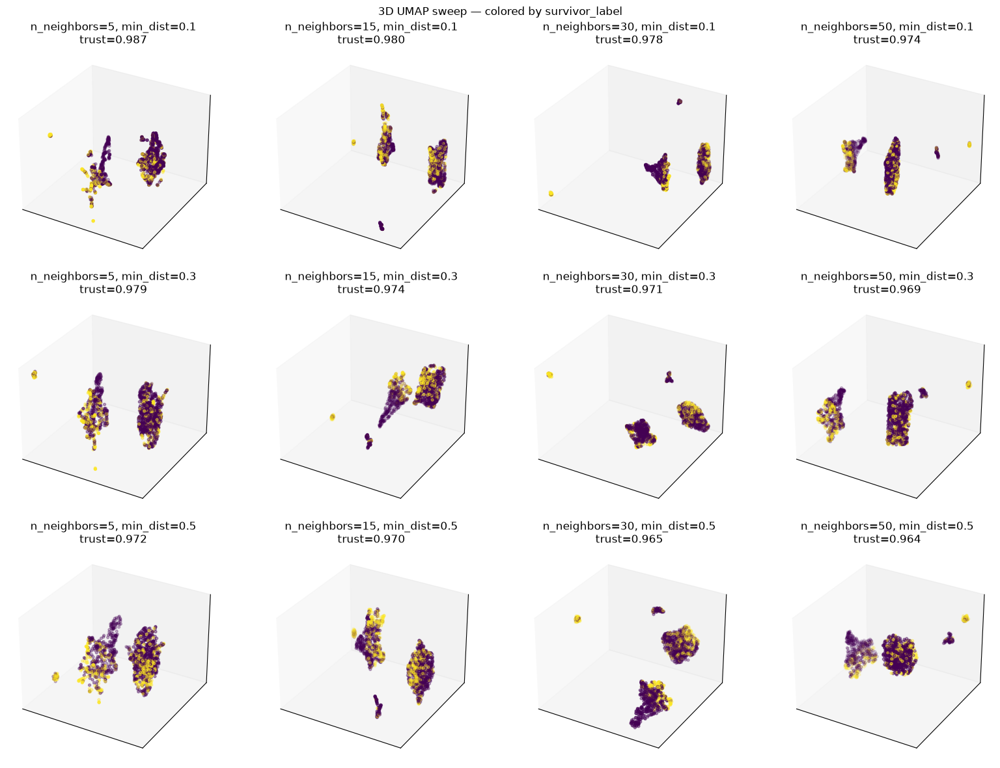


Top 5 by trustworthiness:
  n_neighbors=5, min_dist=0.1: 0.987
  n_neighbors=15, min_dist=0.1: 0.980
  n_neighbors=5, min_dist=0.3: 0.979
  n_neighbors=30, min_dist=0.1: 0.978
  n_neighbors=50, min_dist=0.1: 0.974


In [86]:
# 3Dimensional UMAP sweep with varying n_neighbors and min_dist

n_neighbors = [5, 15, 30, 50]
min_dist = [0.1, 0.3, 0.5]

fig, axes = plt.subplots(len(min_dist), len(n_neighbors),
                         figsize=(16, 12), subplot_kw={'projection': '3d'})
trust_scores = {}

for i, md in enumerate(min_dist):
    for j, nn in enumerate(n_neighbors):
        reducer = UMAP(
            n_neighbors=nn,
            min_dist=md,
            n_components=3,
            random_state=42,
            n_jobs=1,
            compatibility_layout=True
        )
        emb = reducer.fit_transform(x_scaled)
        trust = trustworthiness(x_scaled, emb, n_neighbors=5)
        trust_scores[(nn, md)] = trust

        ax = axes[i, j]
        ax.scatter(emb[:, 0], emb[:, 1], emb[:, 2], c=df['survivor_label'], cmap='viridis', s=8, alpha=0.7)
        ax.set_title(f'n_neighbors={nn}, min_dist={md}\ntrust={trust:.3f}')
        ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

plt.suptitle('3D UMAP sweep — colored by survivor_label')
plt.tight_layout(); plt.show()

# Rank combinations by trustworthiness
sorted_combos = sorted(trust_scores.items(), key=lambda x: -x[1])
print("\nTop 5 by trustworthiness:")
for (nn, md), score in sorted_combos[:5]:
    print(f"  n_neighbors={nn}, min_dist={md}: {score:.3f}")


## Unsupervised Learning (Thermal + Electrical)

### KMeans using x_scaled 

In [148]:
def kmeans_cluster(x_scaled, max_k=13):
    sil_scores = []
    inertias = []

    fig, ax = plt.subplots(3, 4, figsize=(18, 14))

    for k in range(2, max_k+1):
        kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
        cluster_labels = kmeans.fit_predict(x_scaled)
        centroids = kmeans.cluster_centers_

        sil_scores.append(silhouette_score(x_scaled, cluster_labels))
        inertias.append(kmeans.inertia_)

        a = ax[(k-2) // 4, (k-2) % 4]
        sns.scatterplot(x=x_scaled[:,0], y=x_scaled[:,1],
                        hue=cluster_labels, palette='tab10', ax=a)
        a.scatter(centroids[:,0], centroids[:,1], c='black', marker='X', s=100)
        a.set_title(f'k={k}')
        a.grid(True, which='both', linestyle='--', linewidth=0.5)

    plt.tight_layout()
    plt.show()

    fig2, ax2 = plt.subplots(1, 2, figsize=(12, 5))
    ax2[0].plot(range(2, max_k+1), sil_scores, 'o-')
    ax2[0].set_title('Silhouette Scores')
    ax2[0].set_xlabel('k Clusters')
    ax2[0].set_ylabel('Silhouette Score')
    ax2[0].grid(True, which='both', linestyle='--', linewidth=0.5)

    ax2[1].plot(range(2, max_k+1), inertias, 'o-')
    ax2[1].set_title('Inertia')
    ax2[1].set_xlabel('k Clusters')
    ax2[1].set_ylabel('Inertia')
    ax2[1].grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.show()


    # getting the optimal k
    optimal_k = sil_scores.index(max(sil_scores)) + 2
    kmeans = KMeans(n_clusters=optimal_k, n_init=10, random_state=42)
    kmeans.fit_transform(x_scaled)
    cluster_labels = kmeans.labels_

    sns.scatterplot(x=x_scaled[:,0], y=x_scaled[:,1], hue=cluster_labels, palette='tab10')
    plt.title(f"Cluster Labels for Optimal k={optimal_k}")
    plt.show()

    return optimal_k, cluster_labels

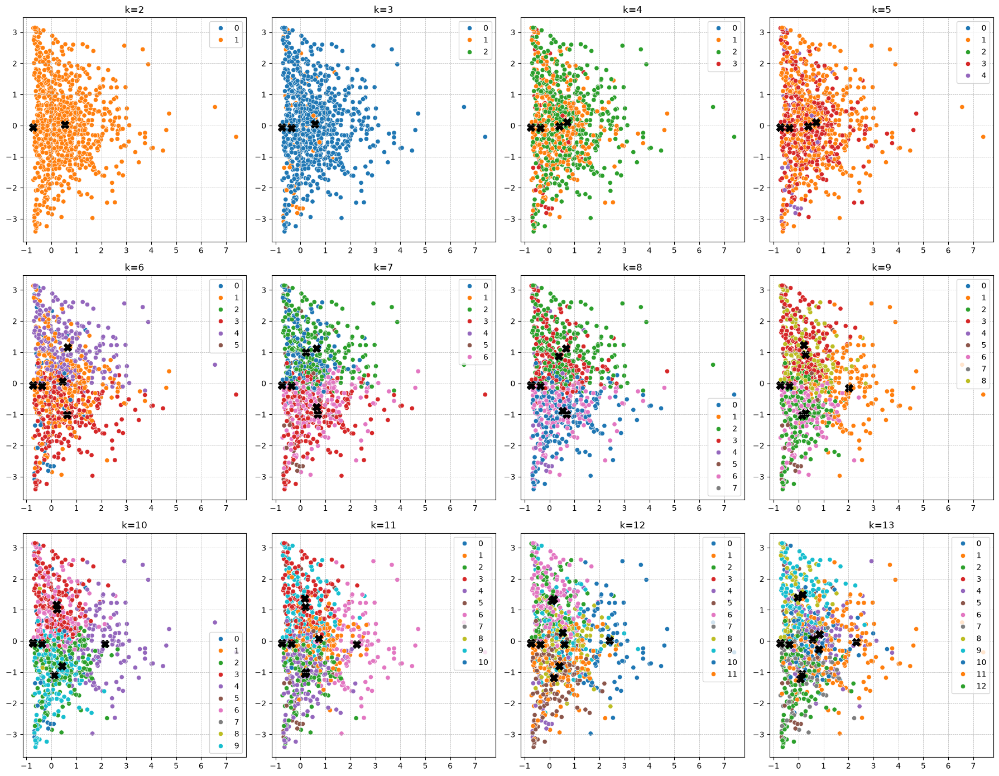

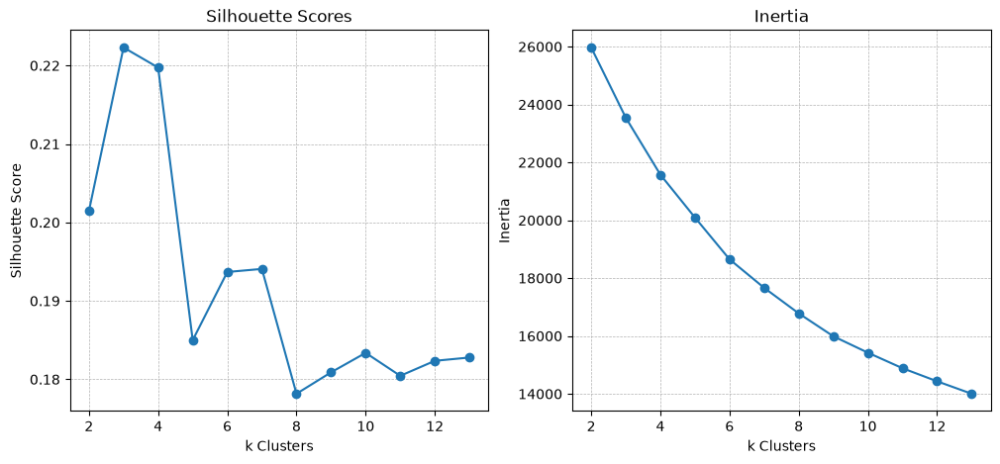

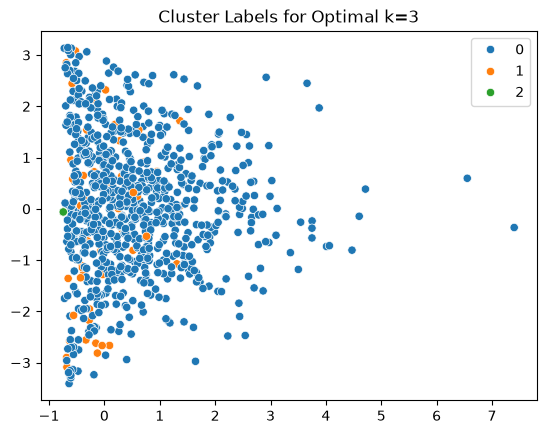

In [149]:
optimal_k, cluster_labels = kmeans_cluster(x_scaled, max_k=13)

### PCA Result + KMeans + t-SNE

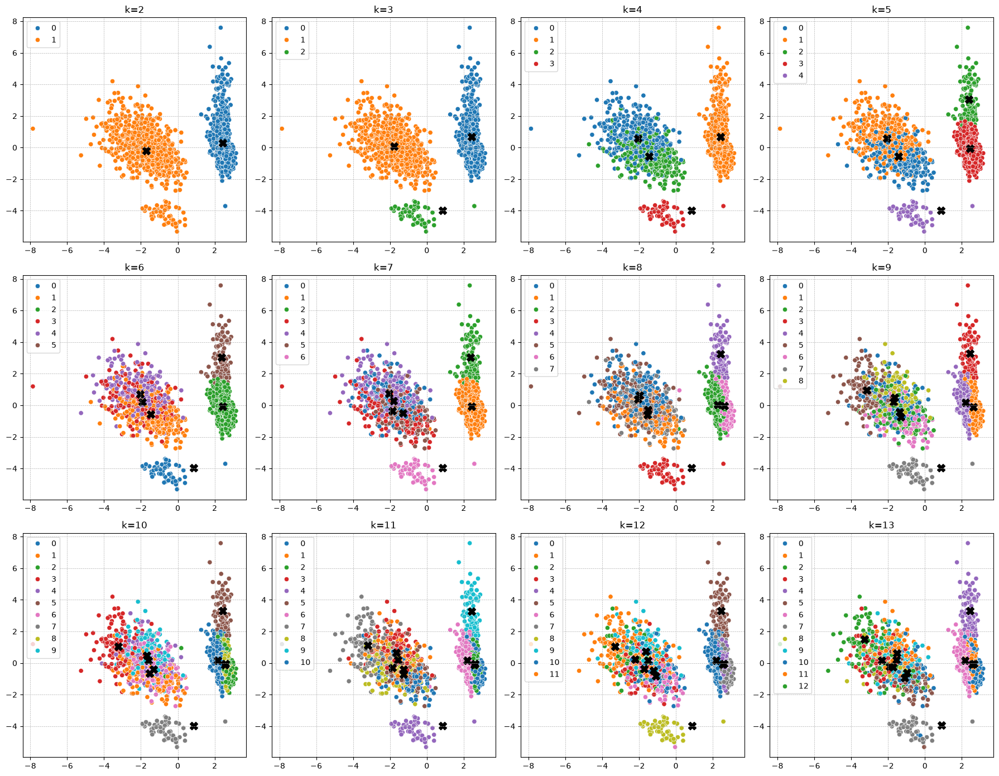

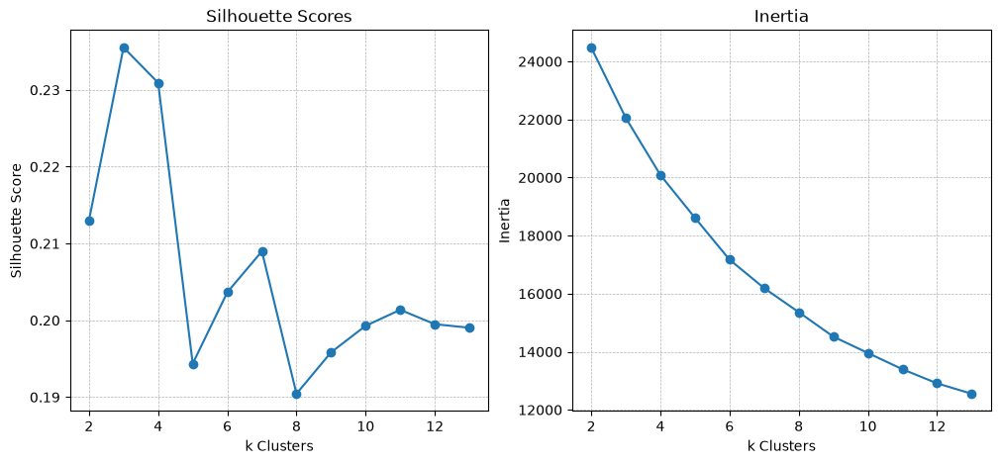

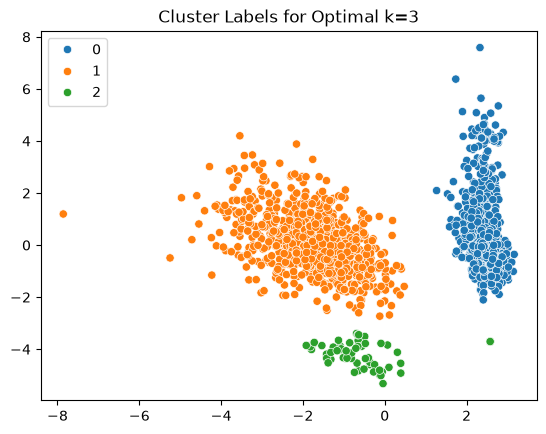

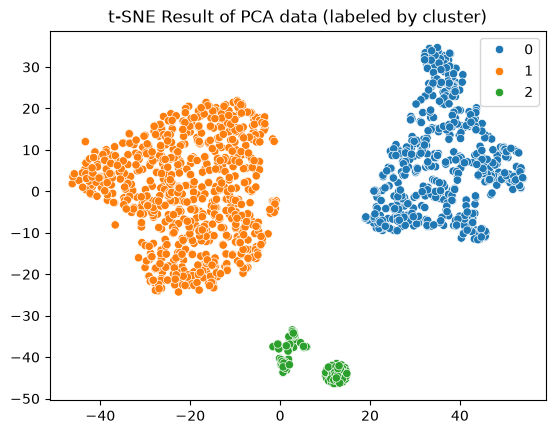

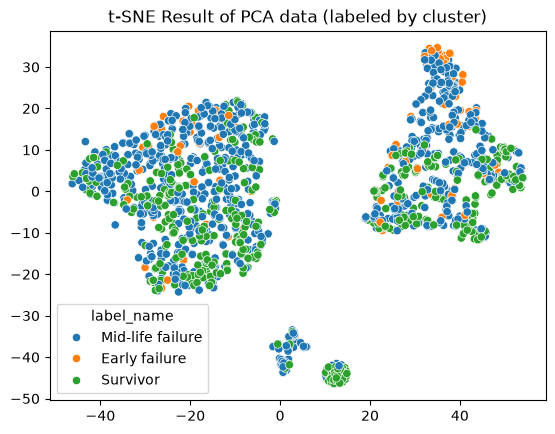

In [193]:
# find the optimize kmeans using pca_result_95_df
optimal_k, cluster_labels = kmeans_cluster(pca_result_95)


# apply t-SNE
tsne = TSNE(n_components=2, random_state=42)
tsne_result = tsne.fit_transform(pca_result_95)

sns.scatterplot(x=tsne_result[:,0], y=tsne_result[:,1], hue=cluster_labels, palette='tab10')
plt.title("t-SNE Result of PCA data (labeled by cluster)")
plt.show()

sns.scatterplot(x=tsne_result[:,0], y=tsne_result[:,1], hue=df['label_name'], palette='tab10')
plt.title("t-SNE Result of PCA data (labeled by cluster)")
plt.show()

### Isomap Result + KMeans + t-SNE

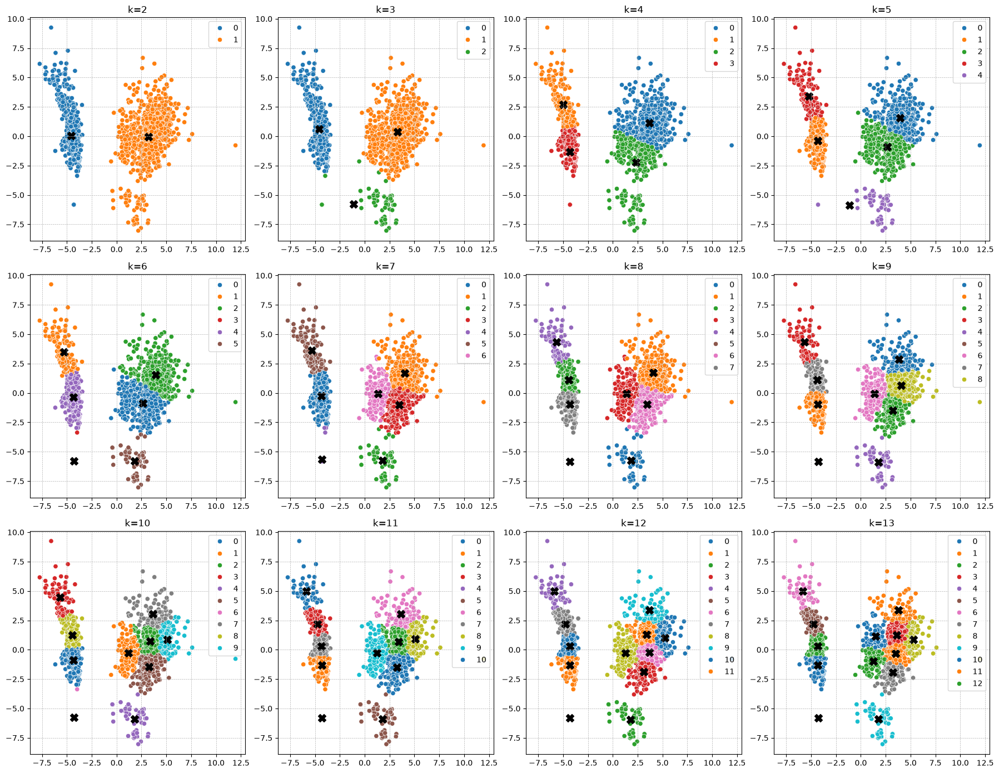

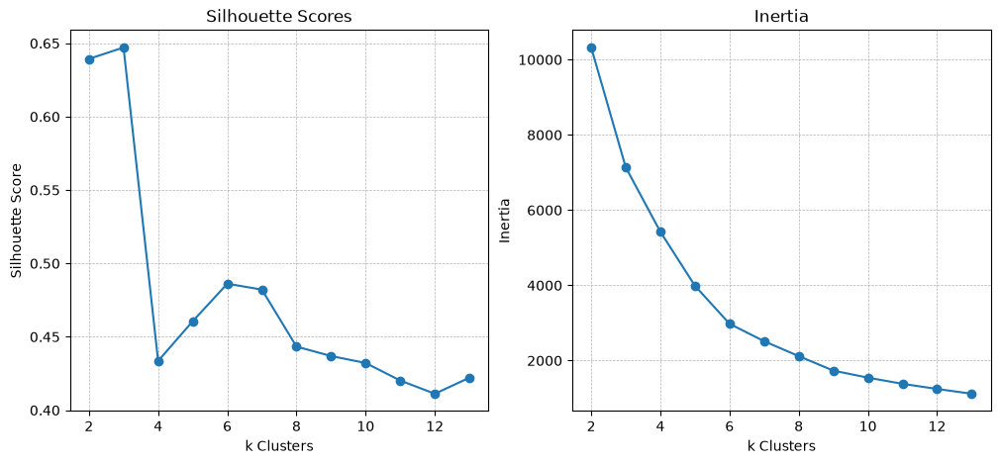

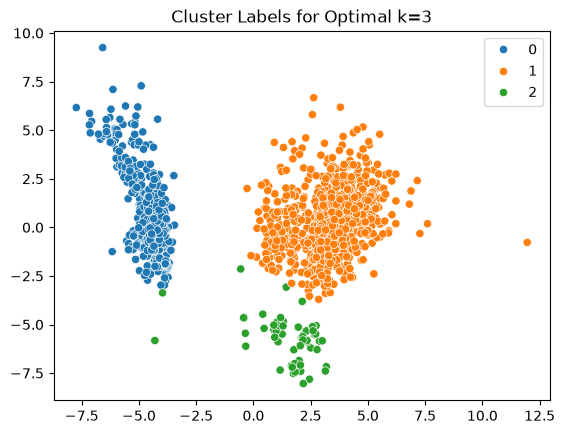

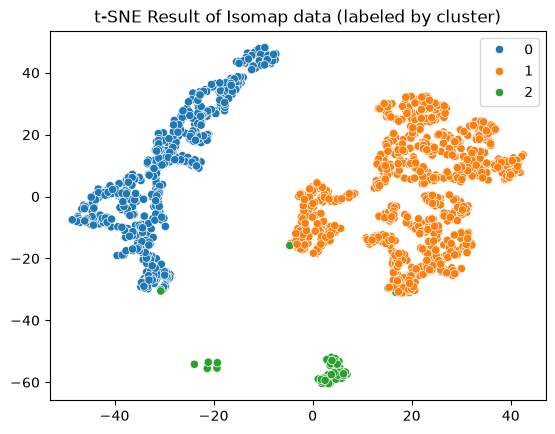

In [156]:
optimal_k, cluster_labels = kmeans_cluster(isomap_result_best, max_k=13)

# apply t-SNE
tsne = TSNE(n_components=2, random_state=42)
tsne_result = tsne.fit_transform(isomap_result_best)

sns.scatterplot(x=tsne_result[:,0], y=tsne_result[:,1], hue=cluster_labels, palette='tab10')
plt.title("t-SNE Result of Isomap data (labeled by cluster)")
plt.show()

### UMAP Result + KMeans + t-SNE

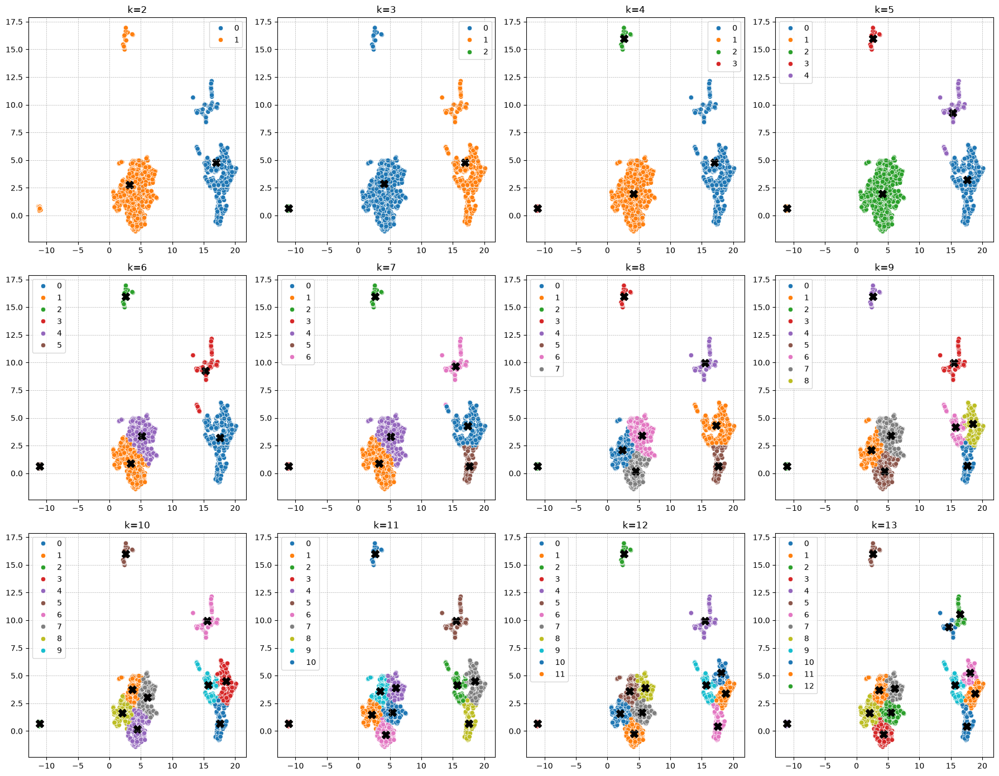

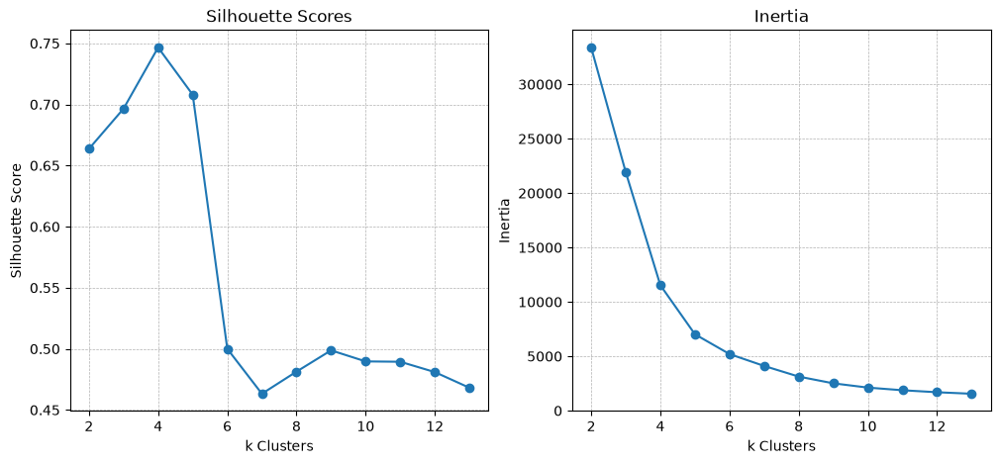

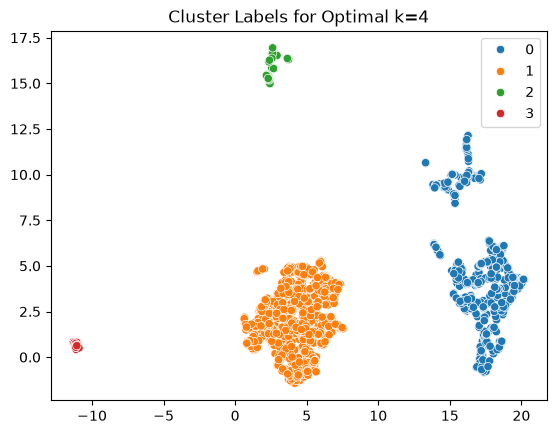

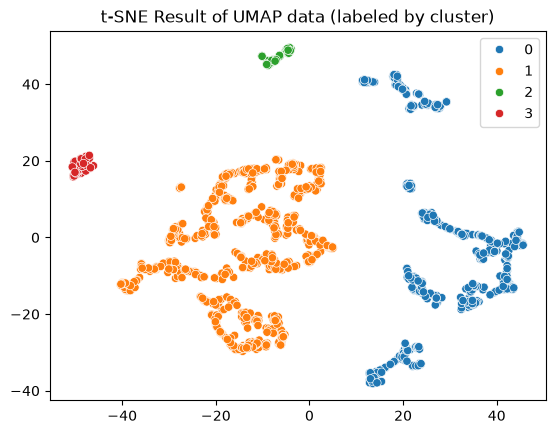

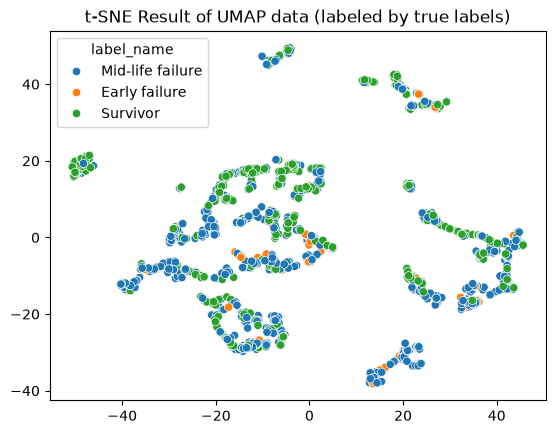

In [194]:
optimal_k, cluster_labels = kmeans_cluster(best_umap, max_k=13)

# apply t-SNE
tsne = TSNE(n_components=2, random_state=42)
tsne_result = tsne.fit_transform(best_umap)

sns.scatterplot(x=tsne_result[:,0], y=tsne_result[:,1], hue=cluster_labels, palette='tab10')
plt.title("t-SNE Result of UMAP data (labeled by cluster)")
plt.show()

sns.scatterplot(x=tsne_result[:,0], y=tsne_result[:,1], hue=df['label_name'], palette='tab10')
plt.title("t-SNE Result of UMAP data (labeled by true labels)")
plt.show()

## Unsupervised Learning (One-hot Encoded based on 'has_thermal_pad')

### Separate per 'has_thermal_pad' Features

In [188]:
# has thermal pad (use only thermal pad features)
df_thpad = df[df['has_thermal_pad'] == 1].copy()
x_thpad = df_thpad[thermal_cols].dropna(axis=0)
x_thpad.head(10)
xth_scaled = StandardScaler().fit_transform(x_thpad)
print(xth_scaled.shape)

# has electrical pad (use only electrical pad features)
df_elpad = df[df['has_thermal_pad'] == 0].copy()
x_elpad = df_elpad[elec_cols].dropna(axis=0)
x_elpad.head(10)
xel_scaled = StandardScaler().fit_transform(x_elpad)
print(xel_scaled.shape)

(908, 11)
(562, 11)


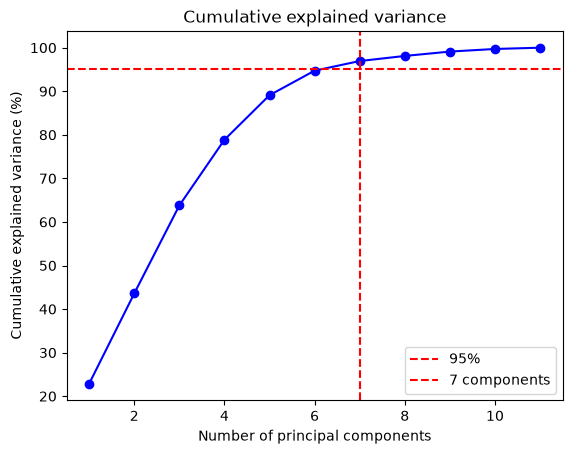

(908, 7)
Number of components for 95% CPV: 7
Shape of PCA result for 95% CPV: (908, 7)


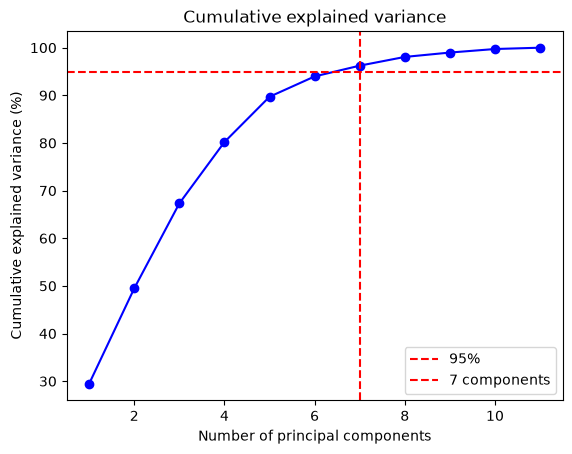

(562, 7)
Number of components for 95% CPV: 7
Shape of PCA result for 95% CPV: (562, 7)


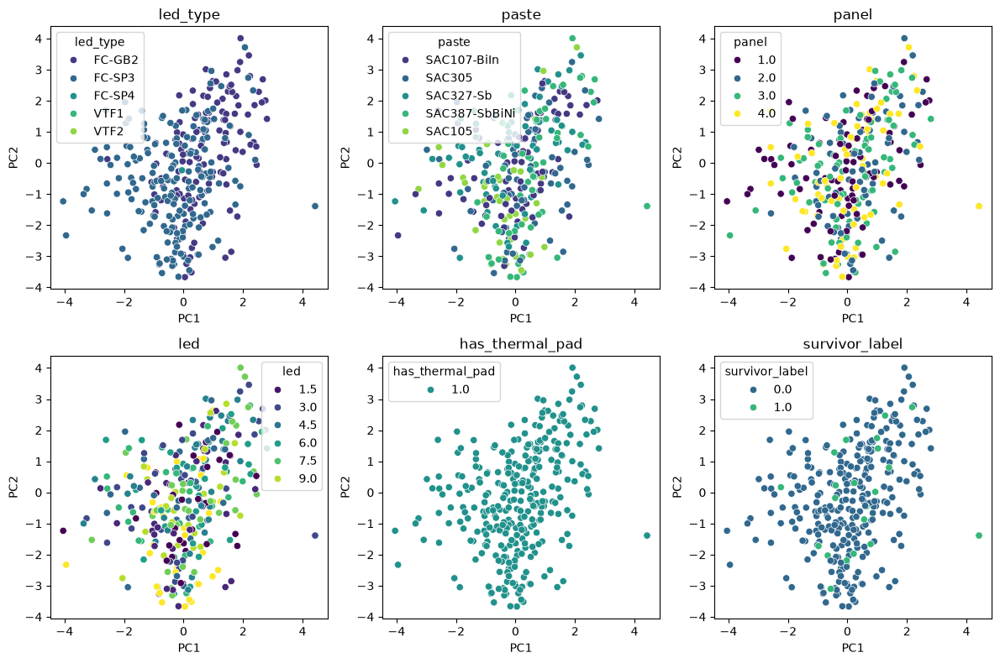

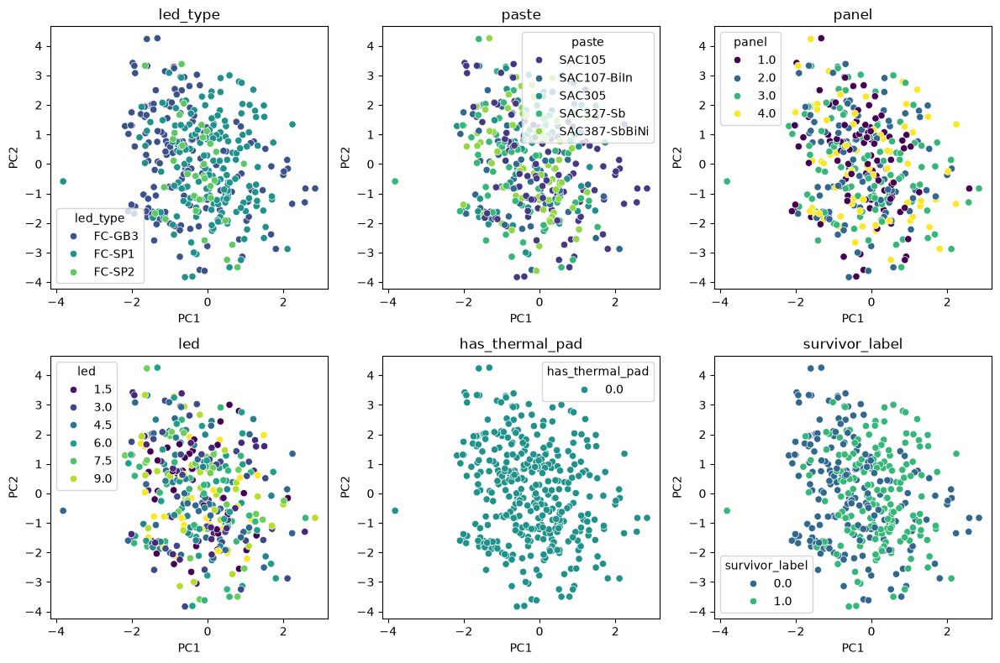

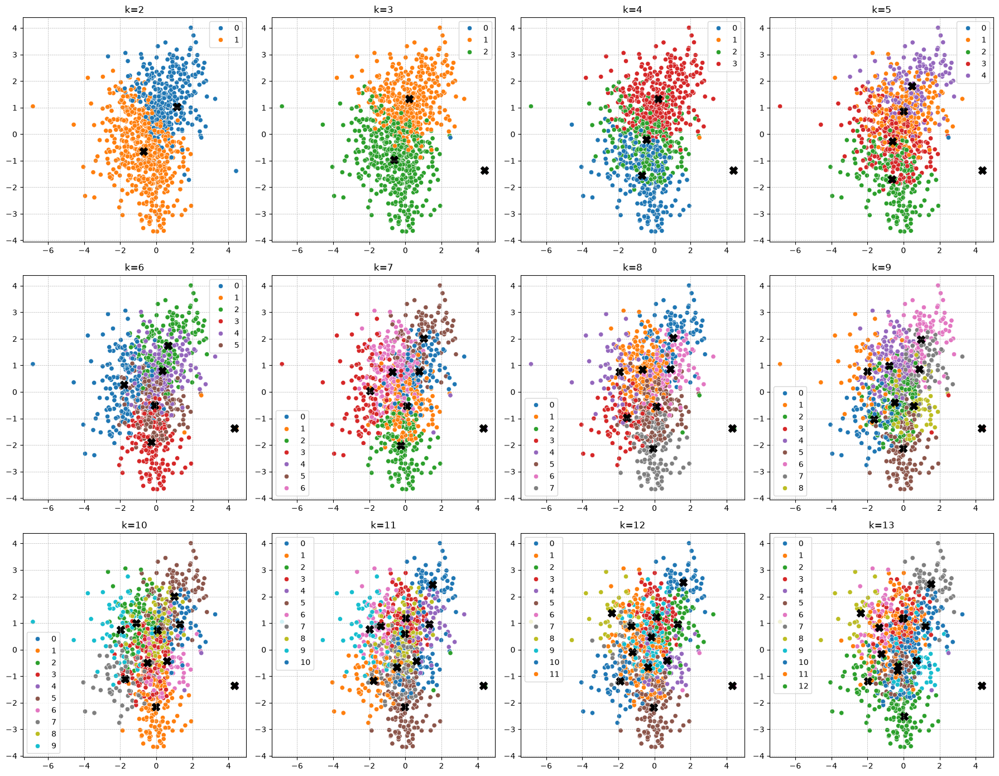

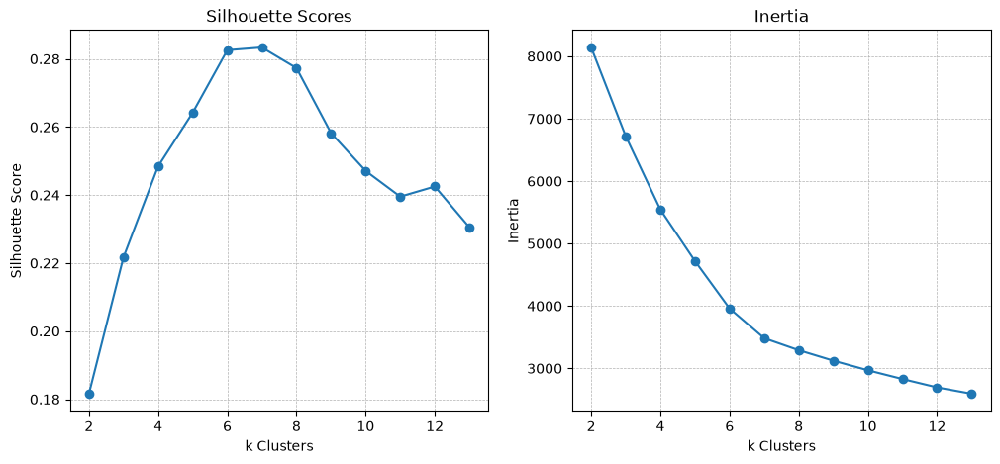

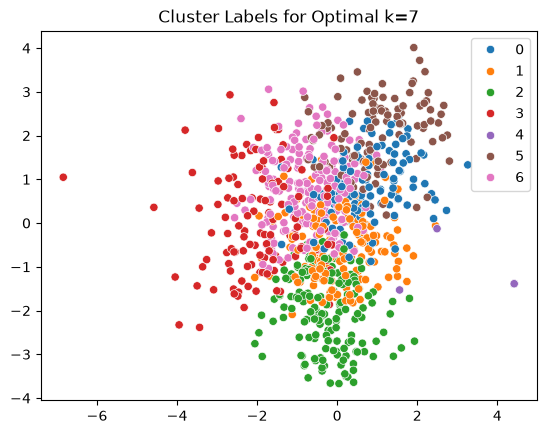

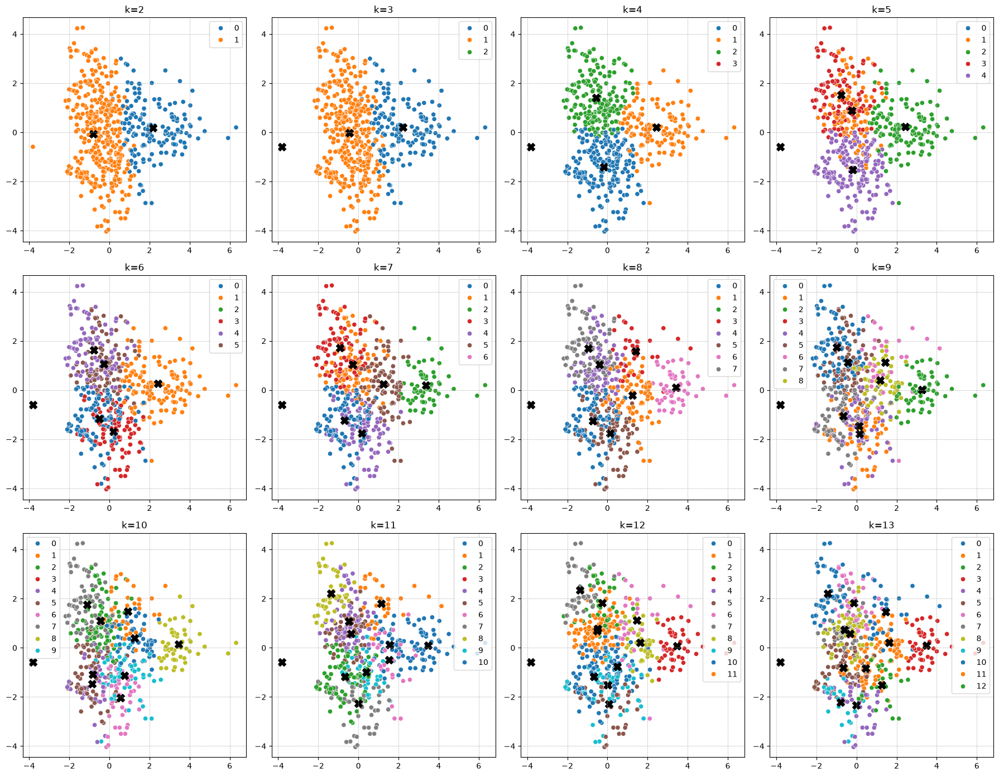

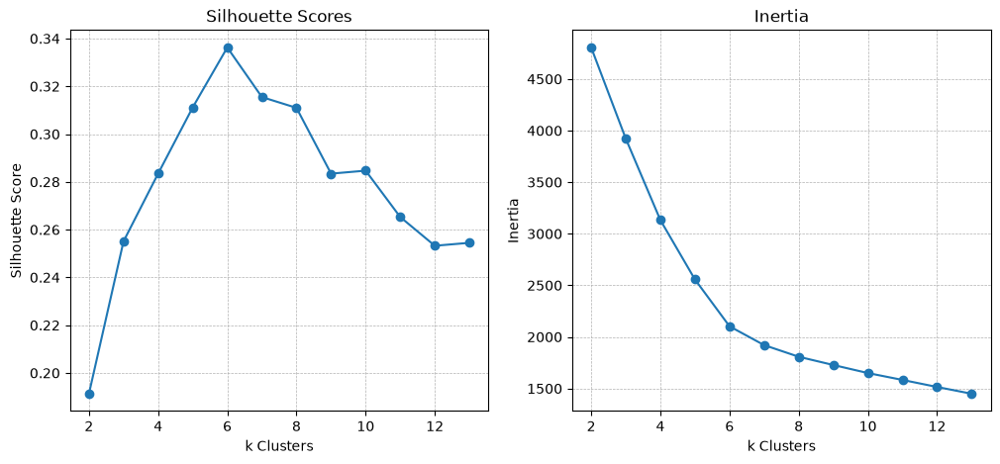

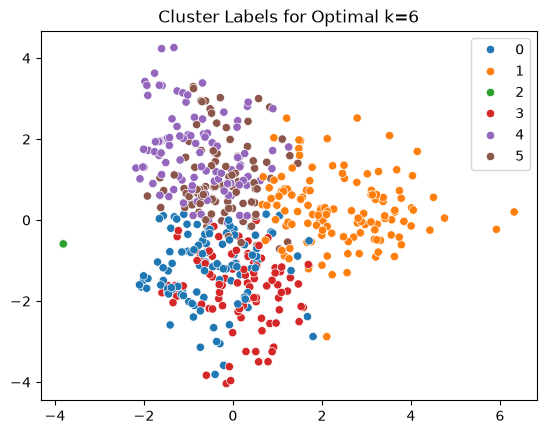

In [191]:
# Separating the PCA, 

th_pca, th_pca_df = pca_analysis(xth_scaled, thermal_cols)
el_pca, el_pca_df = pca_analysis(xel_scaled, elec_cols)

inspect_dimreduction(df_thpad, th_pca_df)
inspect_dimreduction(df_elpad, el_pca_df)

optimal_k_th, clusters_th = kmeans_cluster(th_pca)
optimal_k_el, clusters_el = kmeans_cluster(el_pca)